# Product Analytics in SQL: Retention, Funnels, Sessionization

**What you'll learn**

- How to build the core product-analytics toolkit — DAU/WAU/MAU, stickiness,
  rolling 7-/28-day actives — as distinct-count SQL over a raw events table, and
  why rolling distinct counts don't decompose the way sums do.
- Retention defined *precisely* (N-day bounded vs unbounded vs bracketed), the
  classic cohort retention triangle built entirely in SQL, and how to read curve
  shapes (flattening = a product-market-fit signal; composition shifts = a trap).
- Strictly-ordered funnels with window functions: event sequencing inside a
  conversion window, per-step conversion, and where the strict-order semantics
  silently drop real converters.
- Sessionization from raw timestamps with the `LAG` + cumulative-sum pattern,
  how to justify the 30-minute timeout from the data, and session depth/duration
  metrics that don't lie.
- Growth accounting: classifying every user-month as new / retained /
  resurrected / churned, the MAU bridge identity, and the quick ratio.
- Why averages (average DAU, average days-active) hide the frequency-vs-reach
  distinction and the bimodal engagement distributions that actually drive MAU.

**Why it matters in interviews**

- "Write a query for D7 retention / a signup funnel / sessionize this log" is
  the standard SQL screen for senior product DS roles — and the follow-ups
  ("which retention definition? what denominator?") are where seniority shows.
- Metric-interpretation cases ("DAU is flat but MAU is growing — what's going
  on?") test whether you can decompose a metric into frequency × reach and into
  new/retained/resurrected/churned flows.
- Every analytics-engineering loop probes the classic traps: immature cohorts
  in retention averages, averaging DAU across weekdays, definition-sensitive
  "active user" counts. We demonstrate each one on data where we know the truth.

Everything here runs on DuckDB over a single `events(user_id, event_name, ts)`
table. Window-function mechanics (frames, `QUALIFY`, gaps-and-islands) are
covered in [01_advanced_sql_duckdb.ipynb](./01_advanced_sql_duckdb.ipynb); this
notebook *uses* those tools to answer product questions.

In [1]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 11,
    "figure.constrained_layout.use": True,
})
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

con = duckdb.connect(database=":memory:")


def q(sql: str) -> pd.DataFrame:
    """Run SQL against the in-memory DuckDB and return a pandas DataFrame."""
    return con.execute(sql).df()


# Fixed segment colors (identity follows the entity across every chart).
SEG_COLORS = {"core": "tab:blue", "casual": "tab:orange", "drive_by": "tab:green"}

## 1. Simulating a realistic event log

Per the lab's data policy we *simulate* the product so every metric we compute
can be checked against known ground truth. The product is a subscription
content app (think fitness or language learning): users sign up, open the app,
browse, play and complete content, occasionally hit the paywall, start a
7-day trial, and subscribe.

The generative model bakes in the lifecycle dynamics that real event logs have
and that every technique below is designed to expose:

- **Signup cohorts with growth**: weekly signups grow ~2%/week through 2024.
- **Three latent user segments** with very different engagement:

  | segment | daily activity (start → floor) | weekly churn hazard | share |
  |---|---|---|---|
  | `core` | 0.85 → 0.58 | 0.5% | ~20% → 32% (improving mix) |
  | `casual` | 0.55 → 0.12 | 4% | ~50% |
  | `drive_by` | 0.50 → 0.02 | 24% | the rest |

- **Activity decay**: daily activity probability decays exponentially from the
  start level to the floor with a segment-specific time constant — the classic
  novelty-effect shape.
- **Churn and resurrection**: lifetimes are geometric in weeks (per-user
  heterogeneous hazards); 20% of churned users resurrect weeks later for a
  short, low-intensity comeback.
- **A paid acquisition campaign in weeks 40–51** (from 2024-10-07): signups
  double, but the mix collapses to low-quality users (8% core). This one shock
  will show up in *every* section — MAU, stickiness, retention, growth
  accounting — which is exactly how a real campaign reads in real dashboards.
- **Weekday seasonality**: activity is ~25% lower on weekends.

The analytics below use **only** the raw `events` table. A `users` table with
the latent segment is loaded as *simulation ground truth* — in real life you
don't get to `JOIN` on the truth, but here it lets us verify the stories our
SQL tells.

In [2]:
OBS_START = pd.Timestamp("2024-01-01")          # a Monday
OBS_END = pd.Timestamp("2024-12-31")
END_TS = pd.Timestamp("2024-12-31 23:59:59")
N_DAYS = (OBS_END - OBS_START).days + 1         # 366 (leap year)
N_WEEKS = 52

# --- signup cohorts: organic growth + Q4 campaign shock ---------------------
weeks = np.arange(N_WEEKS)
base_signups = np.round(60 * 1.02 ** weeks).astype(int)
campaign = weeks >= 40                          # campaign weeks 40..51
weekly_signups = np.where(campaign, base_signups * 2, base_signups)
n_users = int(weekly_signups.sum())

signup_week = np.repeat(weeks, weekly_signups)
signup_day = signup_week * 7 + rng.integers(0, 7, n_users)

# --- latent segments: organic mix improves over time; campaign mix is poor ---
w_frac = weeks / (N_WEEKS - 1)
core_share = np.where(campaign, 0.08, 0.20 + 0.12 * w_frac)
drive_share = np.where(campaign, 0.52, 0.30 - 0.12 * w_frac)

u = rng.random(n_users)
pc, pd_ = core_share[signup_week], drive_share[signup_week]
seg = np.where(u < pc, 0, np.where(u > 1 - pd_, 2, 1)).astype(int)  # 0 core, 1 casual, 2 drive_by
SEGMENTS = np.array(["core", "casual", "drive_by"])

# --- segment parameters ------------------------------------------------------
P_START = np.array([0.85, 0.55, 0.50])      # daily activity prob at signup
P_FLOOR = np.array([0.58, 0.12, 0.02])      # asymptotic daily activity prob
TAU = np.array([25.0, 12.0, 4.0])           # decay time constant (days)
HAZARD = np.array([0.005, 0.040, 0.240])    # mean weekly churn hazard
SESS_LAMBDA = np.array([0.50, 0.35, 0.20])  # extra sessions per active day
EV_LAMBDA = np.array([2.6, 2.2, 1.4])       # extra events per session
TRIAL_P = np.array([0.45, 0.25, 0.10])      # P(trial | saw paywall)
SUB_P = np.array([0.65, 0.40, 0.25])        # P(subscribe | trial)

# --- churn: heterogeneous geometric lifetimes (weeks), then days -------------
h_user = np.clip(HAZARD[seg] * rng.lognormal(0.0, 0.35, n_users), 1e-4, 0.95)
lifetime_days = rng.geometric(h_user) * 7

# --- resurrection: 20% of churned users come back for a short stint ----------
resurrect = rng.random(n_users) < 0.20
res_start = signup_day + lifetime_days + 21 + rng.exponential(30, n_users)
res_end = res_start + 10 + rng.exponential(20, n_users)

seg_counts = pd.Series(SEGMENTS[seg]).value_counts()
print(f"users: {n_users:,}  (campaign-period signups: {campaign[signup_week].sum():,})")
print(f"segment mix: {seg_counts.to_dict()}")
print(f"median simulated lifetime (days): "
      f"{pd.Series(lifetime_days).groupby(SEGMENTS[seg]).median().to_dict()}")

users: 7,174  (campaign-period signups: 3,550)
segment mix: {'casual': 3204, 'drive_by': 2730, 'core': 1240}
median simulated lifetime (days): {'casual': 119.0, 'core': 1018.5, 'drive_by': 21.0}


### Daily activity, then sessions, then events

We simulate a user × day activity matrix (alive + decay + weekday effects +
resurrection windows), then expand active user-days into sessions (1+ per
active day) and sessions into events. Each session starts with `app_open` and
continues with events drawn from a catalog at ~3-minute exponential gaps —
which is exactly the structure sessionization (section 5) will try to recover.

In [3]:
day_idx = np.arange(N_DAYS)
dow = day_idx % 7                                   # 0 = Monday (Jan 1 2024)
WEEKDAY_MULT = np.array([1.10, 1.07, 1.04, 1.00, 0.97, 0.80, 0.76])

tenure = day_idx[None, :] - signup_day[:, None]
alive = (tenure >= 0) & (tenure < lifetime_days[:, None])
decay = np.exp(-np.clip(tenure, 0, None) / TAU[seg][:, None])
p_active = P_FLOOR[seg][:, None] + (P_START[seg] - P_FLOOR[seg])[:, None] * decay
p = np.where(alive, p_active, 0.0)

in_res = resurrect[:, None] & (day_idx[None, :] >= res_start[:, None]) \
    & (day_idx[None, :] < res_end[:, None])
p = np.where(in_res, 0.30, p)                       # comeback stints: modest intensity
p = np.clip(p * WEEKDAY_MULT[dow][None, :], 0.0, 0.97)

active = rng.random(p.shape) < p
active[np.arange(n_users), signup_day] = True       # everyone shows up on signup day

u_idx, d_idx = np.nonzero(active)
print(f"active user-days: {u_idx.size:,} "
      f"(avg {u_idx.size / n_users:.1f} per user over the year)")

active user-days: 171,500 (avg 23.9 per user over the year)


In [4]:
# --- sessions ---------------------------------------------------------------
n_sess_day = 1 + rng.poisson(SESS_LAMBDA[seg[u_idx]])
sess_user = np.repeat(u_idx, n_sess_day)
sess_day = np.repeat(d_idx, n_sess_day)
n_sessions = sess_user.size

user_peak = rng.uniform(8, 21, n_users)             # preferred hour of day
hour = np.clip(rng.normal(user_peak[sess_user], 2.2), 0.0, 23.0)
start_sec = np.minimum(hour * 3600 + rng.uniform(0, 3600, n_sessions), 86340.0)

# --- events within sessions -------------------------------------------------
n_ev = 1 + rng.poisson(EV_LAMBDA[seg[sess_user]])   # app_open + extras
tot_ev = int(n_ev.sum())
starts = np.zeros(n_sessions, dtype=np.int64)
starts[1:] = np.cumsum(n_ev)[:-1]
first_mask = np.zeros(tot_ev, dtype=bool)
first_mask[starts] = True

gaps = rng.exponential(180.0, tot_ev)               # ~3 min between in-session events
gaps[first_mask] = 0.0
cs = np.cumsum(gaps)
offset = cs - np.repeat(cs[starts], n_ev)           # grouped cumulative sum

CATALOG = np.array(["browse", "play", "complete", "view_paywall", "profile_edit"])
CATALOG_P = np.array([0.42, 0.34, 0.14, 0.06, 0.04])
names = np.where(first_mask, "app_open", rng.choice(CATALOG, tot_ev, p=CATALOG_P))

ev = pd.DataFrame({
    "user_id": np.repeat(sess_user, n_ev),
    "event_name": names,
    "ts": pd.to_datetime(np.repeat(sess_day, n_ev) * 86400.0
                         + np.repeat(start_sec, n_ev) + offset,
                         unit="s", origin=OBS_START),
})

# --- signup events: 2 minutes before the first session of signup day --------
first_sess_sec = np.full(n_users, 86400.0)
on_signup = sess_day == signup_day[sess_user]
np.minimum.at(first_sess_sec, sess_user[on_signup], start_sec[on_signup])
signups = pd.DataFrame({
    "user_id": np.arange(n_users),
    "event_name": "signup",
    "ts": pd.to_datetime(signup_day * 86400.0 + np.maximum(first_sess_sec - 120.0, 0.0),
                         unit="s", origin=OBS_START),
})

# --- monetization: paywall -> trial (7 days) -> subscribe -------------------
first_paywall = ev.loc[ev["event_name"] == "view_paywall"].groupby("user_id")["ts"].min()
elig = first_paywall.index.to_numpy()
took_trial = rng.random(elig.size) < TRIAL_P[seg[elig]]
trial_users = elig[took_trial]
trial_ts = (first_paywall.loc[trial_users]
            + pd.to_timedelta(rng.exponential(2.0, trial_users.size), unit="D"))
keep = (trial_ts <= END_TS).to_numpy()
trial_users, trial_ts = trial_users[keep], trial_ts[keep]

subbed = rng.random(trial_users.size) < SUB_P[seg[trial_users]]
sub_ts = (trial_ts[subbed] + pd.Timedelta(days=7)
          + pd.to_timedelta(rng.uniform(0, 36, int(subbed.sum())), unit="h"))
keep2 = (sub_ts <= END_TS).to_numpy()
sub_users = trial_users[subbed][keep2]

# a few users subscribe directly, skipping the trial (alternate funnel path)
no_trial = elig[~took_trial]
direct = no_trial[rng.random(no_trial.size) < 0.02]
direct_ts = (first_paywall.loc[direct]
             + pd.to_timedelta(rng.exponential(5.0, direct.size), unit="D"))
dkeep = (direct_ts <= END_TS).to_numpy()

mk = lambda users, name, ts: pd.DataFrame({"user_id": users, "event_name": name, "ts": ts})
events_df = pd.concat([
    ev, signups,
    mk(trial_users, "trial_start", trial_ts.to_numpy()),
    mk(sub_users, "subscribe", sub_ts[keep2].to_numpy()),
    mk(direct[dkeep], "subscribe", direct_ts[dkeep].to_numpy()),
], ignore_index=True)
events_df = events_df.loc[(events_df["ts"] >= OBS_START) & (events_df["ts"] <= END_TS)]
events_df = events_df.sample(frac=1, random_state=7).reset_index(drop=True)  # unsorted, like a real log

users_df = pd.DataFrame({
    "user_id": np.arange(n_users),
    "segment": SEGMENTS[seg],
    "signup_week": signup_week,
    "is_campaign": campaign[signup_week],
})

TRUE_N_SESSIONS = n_sessions
print(f"events: {len(events_df):,}   generated sessions (ground truth): {TRUE_N_SESSIONS:,}")
print(f"subscribers: {sub_users.size + int(dkeep.sum()):,} "
      f"(of whom {int(dkeep.sum())} skipped the trial)")

events: 857,744   generated sessions (ground truth): 246,813
subscribers: 655 (of whom 72 skipped the trial)


In [5]:
con.register("events_df", events_df)
con.register("users_df", users_df)
con.execute("CREATE TABLE events AS SELECT * FROM events_df")
con.execute("CREATE TABLE users  AS SELECT * FROM users_df")

q("""
SELECT event_name,
       COUNT(*)                AS n_events,
       COUNT(DISTINCT user_id) AS n_users,
       MIN(ts)::DATE           AS first_seen,
       MAX(ts)::DATE           AS last_seen
FROM events
GROUP BY 1
ORDER BY n_events DESC
""")

,event_name,n_events,n_users,first_seen,last_seen
0,browse,252858,6676,2024-01-01,2024-12-31
1,app_open,246813,7174,2024-01-01,2024-12-31
2,play,204554,6524,2024-01-01,2024-12-31
3,complete,83811,5643,2024-01-02,2024-12-31
4,view_paywall,36198,4621,2024-01-01,2024-12-31
5,profile_edit,24419,4090,2024-01-03,2024-12-31
6,signup,7174,7174,2024-01-01,2024-12-29
7,trial_start,1262,1262,2024-01-03,2024-12-31
8,subscribe,655,655,2024-01-11,2024-12-30


## 2. Activity metrics: DAU, WAU, MAU, and rolling actives

Definitions first, because interviewers will push on them:

- **DAU(d)** = number of *distinct* users with ≥ 1 qualifying event on calendar
  day `d`. (What counts as "qualifying" is a real decision — see Pitfalls.)
- **Calendar WAU/MAU** = distinct users in a calendar week/month. Simple to
  report, but a step function that only moves at period boundaries.
- **Rolling 7-day / 28-day actives** (WAU7, MAU28) = distinct users in the
  trailing 7/28 days *ending each day*. Smooth, comparable day to day, and 28
  days (not "1 month") avoids month-length artifacts. Most growth teams treat
  MAU28 as *the* MAU.

The key structural fact: **distinct counts are not additive**. WAU is not the
sum (or 7× the average) of DAU, because the same user shows up on several days.
That's why a rolling distinct count can't be computed as a window `SUM` over
daily DAU — you either re-scan a trailing window per day (range join, below) or
use the interval sweep-line trick (next subsection).

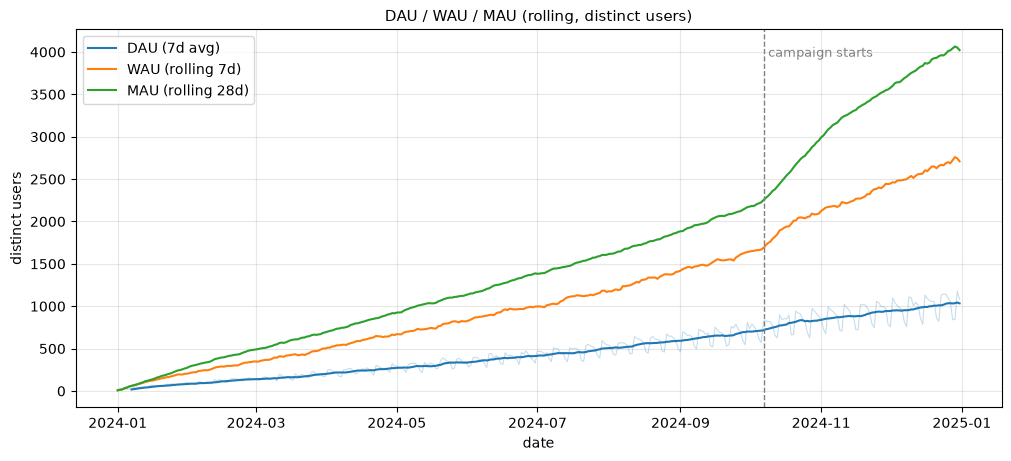

Sep 30 -> Dec 15:  DAU(7d avg) 702 -> 988 (+41%),  MAU28 2169 -> 3836 (+77%)


In [6]:
activity = q("""
WITH daily AS (SELECT DISTINCT user_id, ts::DATE AS day FROM events),
cal AS (
    SELECT range::DATE AS day
    FROM range(DATE '2024-01-01', DATE '2025-01-01', INTERVAL 1 DAY)
)
SELECT c.day,
       COUNT(DISTINCT d.user_id) FILTER (WHERE d.day = c.day)     AS dau,
       COUNT(DISTINCT d.user_id) FILTER (WHERE d.day > c.day - 7) AS wau_7d,
       COUNT(DISTINCT d.user_id)                                  AS mau_28d
FROM cal c
JOIN daily d ON d.day BETWEEN c.day - 27 AND c.day
GROUP BY c.day
ORDER BY c.day
""")
activity["dau_7d_avg"] = activity["dau"].rolling(7).mean()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(activity["day"], activity["dau"], color="tab:blue", alpha=0.25, lw=0.8)
ax.plot(activity["day"], activity["dau_7d_avg"], color="tab:blue", label="DAU (7d avg)")
ax.plot(activity["day"], activity["wau_7d"], color="tab:orange", label="WAU (rolling 7d)")
ax.plot(activity["day"], activity["mau_28d"], color="tab:green", label="MAU (rolling 28d)")
ax.axvline(pd.Timestamp("2024-10-07"), color="gray", ls="--", lw=1)
ax.annotate("campaign starts", (pd.Timestamp("2024-10-09"), activity["mau_28d"].max() * 0.97),
            color="gray", fontsize=9)
ax.set(title="DAU / WAU / MAU (rolling, distinct users)", xlabel="date",
       ylabel="distinct users")
ax.legend(loc="upper left")
plt.show()

camp = activity.set_index("day")
pre, post = camp.loc["2024-09-30"], camp.loc["2024-12-15"]
print(f"Sep 30 -> Dec 15:  DAU(7d avg) {pre['dau_7d_avg']:.0f} -> {post['dau_7d_avg']:.0f} "
      f"({100 * post['dau_7d_avg'] / pre['dau_7d_avg'] - 100:+.0f}%),  "
      f"MAU28 {pre['mau_28d']:.0f} -> {post['mau_28d']:.0f} "
      f"({100 * post['mau_28d'] / pre['mau_28d'] - 100:+.0f}%)")

The chart already contains this notebook's central interview case: after the
campaign starts, **MAU jumps much faster than DAU** — the campaign buys reach
(many users touched in 28 days) but not frequency (little added daily usage,
because the bought users barely stick). We'll quantify that with stickiness and
growth accounting.

### Rolling distinct counts at scale: the sweep-line pattern

The range join above re-scans a 28-day window for each calendar day — fine for
~300k user-days, painful for billions. The scalable pattern reframes the
problem: a user counts toward MAU28 on day `d` iff they had activity in
`[d-27, d]`, i.e. each activity day "covers" the next 28 calendar days. So:
merge each user's activity days into coverage intervals (gaps-and-islands with
a 27-day tolerance — same trick as in
[01_advanced_sql_duckdb.ipynb](./01_advanced_sql_duckdb.ipynb)), emit +1/−1
deltas at interval ends, and take a running sum. One pass, no per-day rescans.

In [7]:
sweep = q("""
WITH daily AS (SELECT DISTINCT user_id, ts::DATE AS day FROM events),
flagged AS (
    SELECT user_id, day,
           CASE WHEN day - LAG(day) OVER (PARTITION BY user_id ORDER BY day) <= 27
                THEN 0 ELSE 1 END AS new_block
    FROM daily
),
blocks AS (
    SELECT user_id, day,
           SUM(new_block) OVER (PARTITION BY user_id ORDER BY day) AS block_id
    FROM flagged
),
coverage AS (            -- maximal intervals during which this user counts as L28-active
    SELECT user_id, block_id, MIN(day) AS cov_start, MAX(day) + 27 AS cov_end
    FROM blocks GROUP BY 1, 2
),
deltas AS (
    SELECT cov_start AS day, +1 AS delta FROM coverage
    UNION ALL
    SELECT cov_end + 1,      -1         FROM coverage
),
net AS (SELECT day, SUM(delta) AS net FROM deltas GROUP BY 1)
SELECT c.day, SUM(COALESCE(n.net, 0)) OVER (ORDER BY c.day) AS mau_28d
FROM (SELECT range::DATE AS day
      FROM range(DATE '2024-01-01', DATE '2025-01-01', INTERVAL 1 DAY)) c
LEFT JOIN net n USING (day)
ORDER BY c.day
""")

assert np.array_equal(sweep["mau_28d"].to_numpy(), activity["mau_28d"].to_numpy()), \
    "sweep-line and range-join MAU28 disagree"
print("sweep-line MAU28 == range-join MAU28 on all 366 days  (identical, as it must be)")

sweep-line MAU28 == range-join MAU28 on all 366 days  (identical, as it must be)


### Stickiness (DAU/MAU) and the pitfalls of averaging DAU

**Stickiness = DAU / MAU** ≈ the average fraction of the monthly-active base
that shows up on a given day — a frequency measure on a 0–1 scale (a user
active every day contributes 1; a once-a-month user contributes ~1/28).

Averaging DAU is where practitioners get burned:

1. **Weekday mix.** DAU has strong day-of-week seasonality; "this week's avg
   DAU vs last week's" moves if the windows contain different weekday mixes,
   and any Mon-vs-Sat comparison is noise by construction.
2. **Average DAU is frequency × reach entangled.** Two products (or segments)
   with the same average DAU can have wildly different user bases: a small
   loyal base or a huge shallow one. Averaging DAU tells you *nothing* about
   how many humans you touch — that's MAU's job. Below, `core` delivers ~2×
   the December DAU of `casual` from a monthly base ~40% *smaller* — same
   "DAU" currency, opposite frequency/reach mix.
3. **avg(DAU)/MAU ≠ avg(DAU/MAU28)** — a ratio-of-averages vs
   average-of-ratios mismatch (small here, but it blows up when MAU trends
   within the month; see `02_ab_testing/05_ratio_metrics_delta_method.ipynb`
   for the general phenomenon).

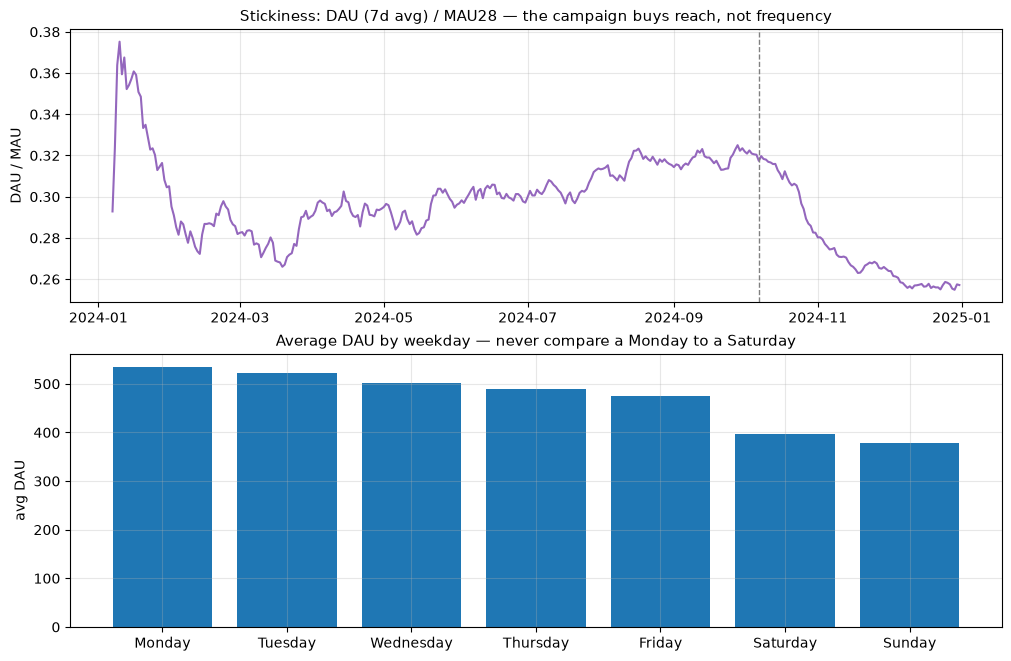

stickiness: Sep 30 = 0.324, Dec 15 = 0.258
weekend DAU vs Mon-Fri: -23%


,segment,avg_dau_dec,mau_dec,stickiness
0,core,625.0,1142,0.547
1,casual,287.0,1948,0.148
2,drive_by,86.0,1040,0.082


In [8]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6.5))
stick = activity["dau_7d_avg"] / activity["mau_28d"]
axes[0].plot(activity["day"], stick, color="tab:purple")
axes[0].axvline(pd.Timestamp("2024-10-07"), color="gray", ls="--", lw=1)
axes[0].set(title="Stickiness: DAU (7d avg) / MAU28 — the campaign buys reach, not frequency",
            ylabel="DAU / MAU")

wd_mean = (activity.assign(weekday=pd.to_datetime(activity["day"]).dt.day_name())
           .groupby("weekday", sort=False)["dau"].mean()
           .reindex(["Monday", "Tuesday", "Wednesday", "Thursday",
                     "Friday", "Saturday", "Sunday"]))
axes[1].bar(wd_mean.index, wd_mean.to_numpy(), color="tab:blue")
axes[1].set(title="Average DAU by weekday — never compare a Monday to a Saturday",
            ylabel="avg DAU", xlabel="")
plt.show()

print(f"stickiness: Sep 30 = {stick[activity['day'] == pd.Timestamp('2024-09-30')].iloc[0]:.3f}, "
      f"Dec 15 = {stick[activity['day'] == pd.Timestamp('2024-12-15')].iloc[0]:.3f}")
print(f"weekend DAU vs Mon-Fri: {100 * wd_mean[['Saturday', 'Sunday']].mean() / wd_mean[:5].mean() - 100:+.0f}%")

# frequency vs reach: December, by (ground-truth) segment
q("""
WITH dec AS (
    SELECT DISTINCT u.segment, e.user_id, e.ts::DATE AS day
    FROM events e JOIN users u USING (user_id)
    WHERE e.ts::DATE BETWEEN DATE '2024-12-01' AND DATE '2024-12-31'
),
dau AS (SELECT segment, day, COUNT(DISTINCT user_id) AS dau FROM dec GROUP BY 1, 2),
mau AS (SELECT segment, COUNT(DISTINCT user_id) AS mau FROM dec GROUP BY 1)
SELECT d.segment,
       ROUND(AVG(d.dau), 0)          AS avg_dau_dec,
       ANY_VALUE(m.mau)              AS mau_dec,
       ROUND(AVG(d.dau) / ANY_VALUE(m.mau), 3) AS stickiness
FROM dau d JOIN mau m USING (segment)
GROUP BY 1
ORDER BY stickiness DESC
""")

## 3. Retention, defined precisely

"Retention" is three different metrics; state which one you mean before writing
SQL. For a user with first-seen day $d_0$ and tenure $n = \text{day} - d_0$:

- **N-day (bounded / classic) retention**: share of the cohort active on
  *exactly* day $n = N$. The consumer-app standard (D1/D7/D30). Noisy per day,
  honest about frequency.
- **Unbounded retention**: share active on day $n \ge N$ ("came back on day N
  *or later*"). Always ≥ bounded, monotone non-increasing in N. Beware: it is
  **right-censored** — for recent cohorts it keeps drifting *up* as more data
  arrives, so yesterday's number is not final.
- **Bracketed retention**: share active in a window, e.g. week 1 = days 1–7.
  The cohort triangle below uses monthly/weekly brackets — the standard
  compromise for low-frequency products.

Two denominator rules that separate senior answers from junior ones:
(1) the denominator is the **full cohort**, not "users who came back at least
once"; (2) a cohort only contributes to horizon $N$ if it has been **observed
for ≥ N days** — otherwise you divide by users who never had the chance.

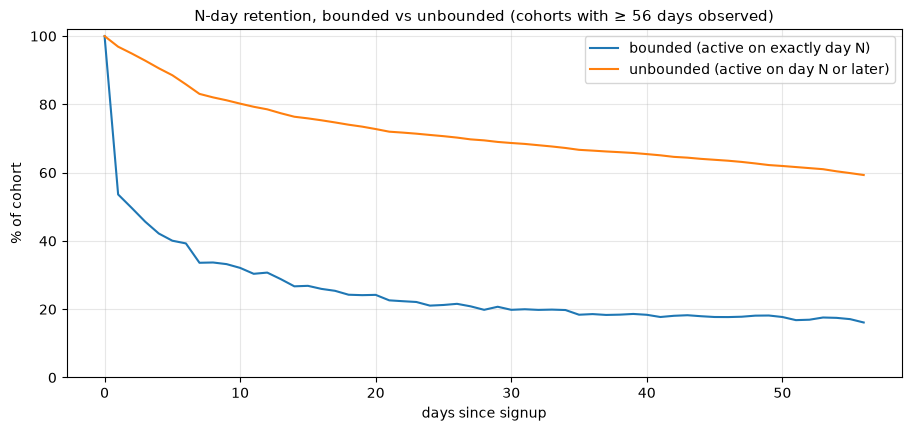

D1:  bounded 53.6%   unbounded 96.9%
D7:  bounded 33.6%   unbounded 83.1%
D28:  bounded 19.8%   unbounded 69.5%


In [9]:
bounded_vs_unbounded = q("""
WITH su AS (
    SELECT user_id, MIN(ts)::DATE AS d0
    FROM events WHERE event_name = 'signup' GROUP BY 1
),
mature AS (SELECT * FROM su WHERE d0 <= DATE '2024-12-31' - 56),  -- >= 56 days observed
act AS (SELECT DISTINCT user_id, ts::DATE AS day FROM events),
tenure AS (
    SELECT m.user_id, (a.day - m.d0)::INT AS n
    FROM mature m JOIN act a USING (user_id)
    WHERE a.day >= m.d0
),
last AS (SELECT user_id, MAX(n) AS last_n FROM tenure GROUP BY 1),
grid AS (SELECT range::INT AS n FROM range(0, 57)),
b AS (SELECT n, COUNT(DISTINCT user_id) AS on_n FROM tenure WHERE n <= 56 GROUP BY 1),
u AS (SELECT g.n, COUNT(*) AS on_or_after FROM grid g JOIN last l ON l.last_n >= g.n GROUP BY 1)
SELECT g.n AS day_n,
       100.0 * COALESCE(b.on_n, 0)        / (SELECT COUNT(*) FROM mature) AS bounded_pct,
       100.0 * COALESCE(u.on_or_after, 0) / (SELECT COUNT(*) FROM mature) AS unbounded_pct
FROM grid g LEFT JOIN b USING (n) LEFT JOIN u ON u.n = g.n
ORDER BY 1
""")

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(bounded_vs_unbounded["day_n"], bounded_vs_unbounded["bounded_pct"],
        color="tab:blue", label="bounded (active on exactly day N)")
ax.plot(bounded_vs_unbounded["day_n"], bounded_vs_unbounded["unbounded_pct"],
        color="tab:orange", label="unbounded (active on day N or later)")
ax.set(title="N-day retention, bounded vs unbounded (cohorts with ≥ 56 days observed)",
       xlabel="days since signup", ylabel="% of cohort", ylim=(0, 102))
ax.legend()
plt.show()

r = bounded_vs_unbounded.set_index("day_n")
for n in (1, 7, 28):
    print(f"D{n}:  bounded {r.loc[n, 'bounded_pct']:.1f}%   unbounded {r.loc[n, 'unbounded_pct']:.1f}%")

The two curves answer different questions: bounded ≈ "what fraction uses the
product on a given tenure day" (a frequency statement, which is why it sits at
roughly stickiness level once decayed), unbounded ≈ "what fraction has not yet
permanently left" (a survival statement — the natural input to LTV, see
[../08_product_analytics/03_ltv_modeling.ipynb](../08_product_analytics/03_ltv_modeling.ipynb)).
Quoting unbounded numbers where the audience expects bounded ones overstates
retention severalfold (~2.5× at D7 here, ~3.5× at D28) — a classic dashboard
crime.

### The cohort retention triangle

The triangle is the standard artifact: one row per signup cohort, one column
per period since signup, each cell = % of the cohort active in that period.
It separates **tenure effects** (read along a row) from **cohort quality**
(read down a column) — the two things a single blended retention number
confounds. We build it in one SQL statement at monthly grain (month 0 is
definitionally 100%, so we display from month 1).

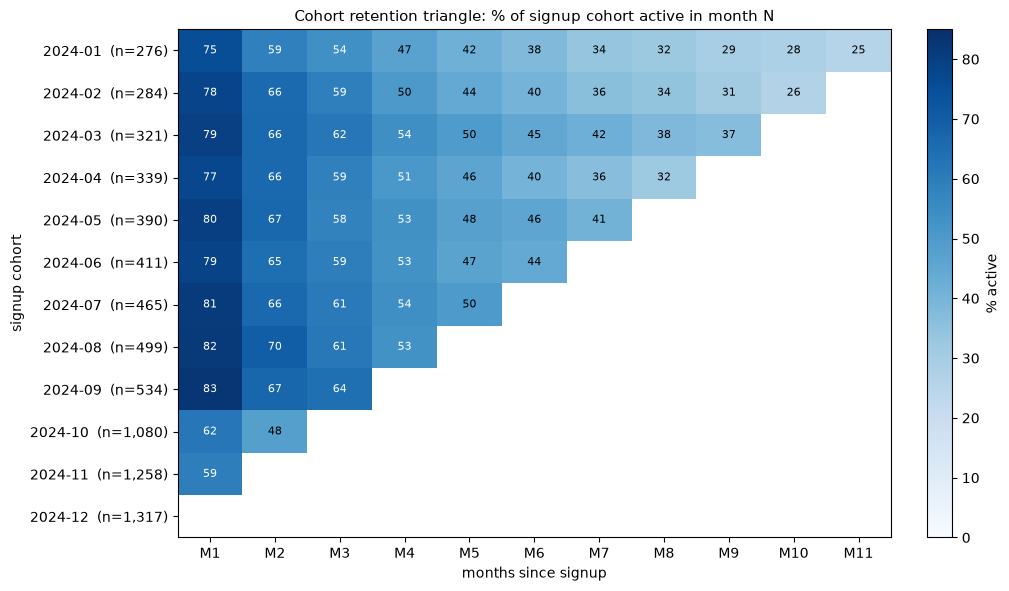

In [10]:
tri_long = q("""
WITH su AS (
    SELECT user_id, date_trunc('month', MIN(ts))::DATE AS cohort_month
    FROM events WHERE event_name = 'signup' GROUP BY 1
),
sizes AS (SELECT cohort_month, COUNT(*) AS cohort_size FROM su GROUP BY 1),
act AS (
    SELECT DISTINCT user_id, date_trunc('month', ts)::DATE AS act_month FROM events
),
ret AS (
    SELECT su.cohort_month,
           datediff('month', su.cohort_month, a.act_month) AS month_n,
           COUNT(DISTINCT a.user_id) AS actives
    FROM su JOIN act a USING (user_id)
    WHERE a.act_month >= su.cohort_month
    GROUP BY 1, 2
)
SELECT r.cohort_month, r.month_n, r.actives, s.cohort_size,
       100.0 * r.actives / s.cohort_size AS retention_pct
FROM ret r JOIN sizes s USING (cohort_month)
ORDER BY 1, 2
""")

tri = tri_long.pivot(index="cohort_month", columns="month_n", values="retention_pct")
sizes = tri_long.groupby("cohort_month")["cohort_size"].first()
shown = tri.iloc[:, 1:]                      # drop month 0 (= 100% by definition)
vals = shown.to_numpy(dtype=float)

fig, ax = plt.subplots(figsize=(10, 5.8))
vmax = np.ceil(np.nanmax(vals) / 5) * 5
im = ax.imshow(vals, cmap="Blues", vmin=0, vmax=vmax, aspect="auto")
for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        if not np.isnan(vals[i, j]):
            ax.text(j, i, f"{vals[i, j]:.0f}", ha="center", va="center", fontsize=8,
                    color="white" if vals[i, j] > 0.6 * vmax else "black")
ax.set_xticks(range(vals.shape[1]), [f"M{c}" for c in shown.columns])
ax.set_yticks(range(vals.shape[0]),
              [f"{m.strftime('%Y-%m')}  (n={sizes[m]:,})" for m in shown.index])
ax.set(title="Cohort retention triangle: % of signup cohort active in month N",
       xlabel="months since signup", ylabel="signup cohort")
ax.grid(False)
fig.colorbar(im, ax=ax, label="% active")
plt.show()

How a senior candidate reads this triangle:

- **Along a row** (tenure): a steep early cliff (the January cohort goes
  100 → 75 → 59 by month 2), after which the decline **decelerates by an
  order of magnitude** — from month 8 on the cohort leaks only ~1–2 pts per
  month. That deceleration toward a plateau is the classic quantitative
  product-market-fit signal; a curve that keeps sliding toward zero at a
  constant rate means you are renting users, and no acquisition spend fixes
  that.
- **Down a column** (cohort quality): month-1 retention *improves* through
  the Jan→Sep cohorts, 75% → 83% (our simulated organic mix shifts toward
  core users), then **collapses to ~60% for the Oct–Nov campaign cohorts**.
  The triangle catches in one glance what a blended retention metric would
  smear into a mild average decline.
- The **asymptote level** is a composition statement: it is roughly
  (share of habitual users) × (their bracket-level activity probability). To
  move it you either acquire different users or change the habit loop — two
  different roadmaps.

Same data, curve view, weekly grain — cohorts grouped by signup quarter, each
cohort-week contributing only fully-observed weeks:

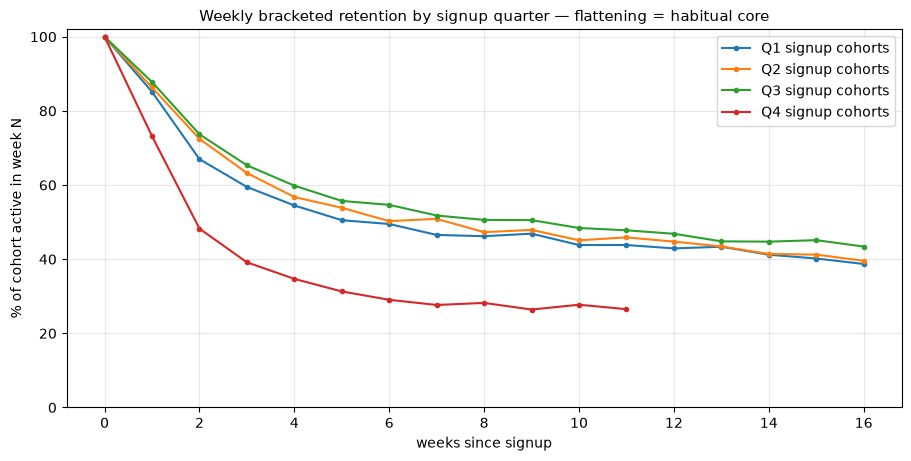

quarter  retention_pct
     Q1           46.2
     Q2           47.3
     Q3           50.6
     Q4           28.2

Q1 weekly loss: weeks 1-4 = 10.2 pts/week, weeks 10-16 = 0.9 pts/week — the curve is leveling out


In [11]:
wk_long = q("""
WITH su AS (
    SELECT user_id, date_trunc('week', MIN(ts))::DATE AS cohort_week
    FROM events WHERE event_name = 'signup' GROUP BY 1
),
sizes AS (SELECT cohort_week, COUNT(*) AS cohort_size FROM su GROUP BY 1),
act AS (
    SELECT DISTINCT user_id, date_trunc('week', ts)::DATE AS act_week
    FROM events WHERE ts < TIMESTAMP '2024-12-30 00:00:00'   -- drop the partial final week
),
ret AS (
    SELECT su.cohort_week, (a.act_week - su.cohort_week) // 7 AS week_n,
           COUNT(DISTINCT a.user_id) AS actives
    FROM su JOIN act a USING (user_id)
    WHERE a.act_week >= su.cohort_week
    GROUP BY 1, 2
)
SELECT r.cohort_week, r.week_n, r.actives, s.cohort_size
FROM ret r JOIN sizes s USING (cohort_week)
WHERE r.cohort_week + (r.week_n * 7 + 6)::INT <= DATE '2024-12-29'   -- week fully observed
ORDER BY 1, 2
""")
wk_long["quarter"] = "Q" + ((wk_long["cohort_week"].dt.month - 1) // 3 + 1).astype(str)

curves = (wk_long[wk_long["week_n"] <= 16]
          .groupby(["quarter", "week_n"])[["actives", "cohort_size"]].sum()
          .assign(retention_pct=lambda d: 100 * d["actives"] / d["cohort_size"])
          .reset_index())

fig, ax = plt.subplots(figsize=(9, 4.5))
qcolors = {"Q1": "tab:blue", "Q2": "tab:orange", "Q3": "tab:green", "Q4": "tab:red"}
for quarter, g in curves.groupby("quarter"):
    ax.plot(g["week_n"], g["retention_pct"], marker="o", ms=3,
            color=qcolors[quarter], label=f"{quarter} signup cohorts")
ax.set(title="Weekly bracketed retention by signup quarter — flattening = habitual core",
       xlabel="weeks since signup", ylabel="% of cohort active in week N",
       ylim=(0, 102), xticks=range(0, 17, 2))
ax.legend(title=None)
plt.show()

print(curves[curves["week_n"] == 8][["quarter", "retention_pct"]].round(1).to_string(index=False))
q1 = curves.loc[curves["quarter"] == "Q1"].set_index("week_n")["retention_pct"]
print(f"\nQ1 weekly loss: weeks 1-4 = {(q1[1] - q1[4]) / 3:.1f} pts/week, "
      f"weeks 10-16 = {(q1[10] - q1[16]) / 6:.1f} pts/week — the curve is leveling out")

Q1→Q3 cohorts flatten at successively *higher* levels (the improving organic
mix), while Q4 collapses — same campaign story, tenure-aligned view. Note the
trap this sets up: any *blended* retention curve pools these four very
different populations. That's Pitfall 1 below, and conceptually it's the same
mix-shift/Simpson mechanics as
[../01_statistical_foundations/04_statistical_traps.ipynb](../01_statistical_foundations/04_statistical_traps.ipynb).

## 4. Funnels: strictly-ordered steps within a conversion window

Funnel: `signup → play → view_paywall → trial_start → subscribe`, all within
**30 days of signup**, with **strict ordering** — each step must occur *after*
the (first qualifying) previous step. Semantics to state out loud in an
interview, because each is a real decision:

- **Entry anchor**: the window is anchored at signup. Users signing up after
  Dec 1 can't be observed for a full window, so we exclude them — otherwise
  the newest cohorts drag conversion down mechanically.
- **Strict order**: a paywall view *before* first play does not count. Strict
  funnels measure the intended path, not goal attainment (we quantify the gap
  below).
- **Greedy matching**: we take the *earliest* qualifying event per step. With
  the window anchored at a unique step-1 event this is provably safe (earliest
  choices maximize the time left for later steps). Caution: if instead the
  window were anchored at a *repeatable* step-1 event, greedy first-match can
  miss sequences that a later anchor would satisfy — you'd need per-anchor
  logic.

The window-function implementation stacks one layer per step: each layer
computes `MIN(ts) FILTER/CASE (event = step_k AND ts > prev_step_ts AND within
window) OVER (PARTITION BY user_id)`. `NULL`s cascade, so a user missing step
k has `NULL` for all later steps — exactly funnel semantics.

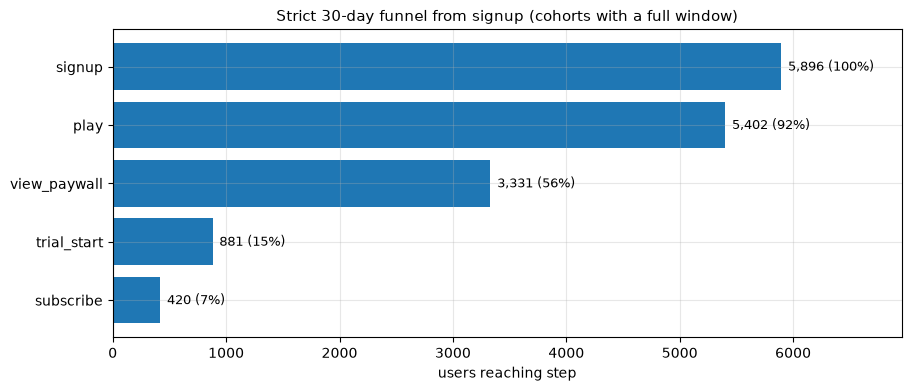

,users,pct_of_signups,pct_of_prev_step
1_signup,5896,100.0,NaN
2_play,5402,91.6,91.6
3_view_paywall,3331,56.5,61.7
4_trial_start,881,14.9,26.4
5_subscribe,420,7.1,47.7


In [12]:
con.execute("""
CREATE OR REPLACE TEMP TABLE funnel_users AS
WITH e1 AS (
    SELECT user_id, event_name, ts,
           MIN(CASE WHEN event_name = 'signup' THEN ts END)
               OVER (PARTITION BY user_id) AS t_signup
    FROM events
),
e2 AS (
    SELECT *, MIN(CASE WHEN event_name = 'play'
                        AND ts > t_signup
                        AND ts <= t_signup + INTERVAL 30 DAY THEN ts END)
              OVER (PARTITION BY user_id) AS t_play
    FROM e1
),
e3 AS (
    SELECT *, MIN(CASE WHEN event_name = 'view_paywall'
                        AND ts > t_play
                        AND ts <= t_signup + INTERVAL 30 DAY THEN ts END)
              OVER (PARTITION BY user_id) AS t_paywall
    FROM e2
),
e4 AS (
    SELECT *, MIN(CASE WHEN event_name = 'trial_start'
                        AND ts > t_paywall
                        AND ts <= t_signup + INTERVAL 30 DAY THEN ts END)
              OVER (PARTITION BY user_id) AS t_trial
    FROM e3
),
e5 AS (
    SELECT *, MIN(CASE WHEN event_name = 'subscribe'
                        AND ts > t_trial
                        AND ts <= t_signup + INTERVAL 30 DAY THEN ts END)
              OVER (PARTITION BY user_id) AS t_sub
    FROM e4
)
SELECT DISTINCT user_id, t_signup, t_play, t_paywall, t_trial, t_sub
FROM e5
WHERE t_signup <= TIMESTAMP '2024-12-01 23:59:59'   -- full 30-day window observable
""")

steps = q("""
SELECT COUNT(*)          AS "1_signup",
       COUNT(t_play)     AS "2_play",
       COUNT(t_paywall)  AS "3_view_paywall",
       COUNT(t_trial)    AS "4_trial_start",
       COUNT(t_sub)      AS "5_subscribe"
FROM funnel_users
""").T.rename(columns={0: "users"})
steps["pct_of_signups"] = (100 * steps["users"] / steps["users"].iloc[0]).round(1)
steps["pct_of_prev_step"] = (100 * steps["users"] / steps["users"].shift(1)).round(1)

fig, ax = plt.subplots(figsize=(9, 3.8))
labels = [s.split("_", 1)[1] for s in steps.index]
ax.barh(range(len(steps))[::-1], steps["users"], color="tab:blue")
for i, (n_u, pct) in enumerate(zip(steps["users"], steps["pct_of_signups"])):
    ax.text(n_u + steps["users"].iloc[0] * 0.01, len(steps) - 1 - i,
            f"{n_u:,} ({pct:.0f}%)", va="center", fontsize=9)
ax.set_yticks(range(len(steps))[::-1], labels)
ax.set(title="Strict 30-day funnel from signup (cohorts with a full window)",
       xlabel="users reaching step", xlim=(0, steps['users'].iloc[0] * 1.18))
plt.show()

steps

The same funnel as chained CTEs — one aggregate `MIN` per step, each
constrained by the previous step's timestamp. This is the formulation most
interviewers expect at a whiteboard; it must (and does) agree exactly with the
window-function version.

In [13]:
chained = q("""
WITH p0 AS (
    SELECT user_id, MIN(ts) AS t0
    FROM events
    WHERE event_name = 'signup' AND ts <= TIMESTAMP '2024-12-01 23:59:59'
    GROUP BY 1
),
p1 AS (
    SELECT p0.user_id, p0.t0, MIN(e.ts) AS t1
    FROM p0 JOIN events e ON e.user_id = p0.user_id
     AND e.event_name = 'play'
     AND e.ts > p0.t0 AND e.ts <= p0.t0 + INTERVAL 30 DAY
    GROUP BY 1, 2
),
p2 AS (
    SELECT p1.user_id, p1.t0, MIN(e.ts) AS t2
    FROM p1 JOIN events e ON e.user_id = p1.user_id
     AND e.event_name = 'view_paywall'
     AND e.ts > p1.t1 AND e.ts <= p1.t0 + INTERVAL 30 DAY
    GROUP BY 1, 2
),
p3 AS (
    SELECT p2.user_id, p2.t0, MIN(e.ts) AS t3
    FROM p2 JOIN events e ON e.user_id = p2.user_id
     AND e.event_name = 'trial_start'
     AND e.ts > p2.t2 AND e.ts <= p2.t0 + INTERVAL 30 DAY
    GROUP BY 1, 2
),
p4 AS (
    SELECT p3.user_id, p3.t0, MIN(e.ts) AS t4
    FROM p3 JOIN events e ON e.user_id = p3.user_id
     AND e.event_name = 'subscribe'
     AND e.ts > p3.t3 AND e.ts <= p3.t0 + INTERVAL 30 DAY
    GROUP BY 1, 2
)
SELECT (SELECT COUNT(*) FROM p0) AS s1, (SELECT COUNT(*) FROM p1) AS s2,
       (SELECT COUNT(*) FROM p2) AS s3, (SELECT COUNT(*) FROM p3) AS s4,
       (SELECT COUNT(*) FROM p4) AS s5
""")
assert chained.iloc[0].tolist() == steps["users"].tolist(), "funnel implementations disagree"
print("chained-CTE funnel == window-function funnel:", chained.iloc[0].tolist())

q("""
SELECT ROUND(median(datediff('hour', t_signup, t_play)) / 24.0, 2)    AS med_days_to_play,
       ROUND(median(datediff('hour', t_signup, t_paywall)) / 24.0, 2) AS med_days_to_paywall,
       ROUND(median(datediff('hour', t_signup, t_trial)) / 24.0, 2)   AS med_days_to_trial,
       ROUND(median(datediff('hour', t_signup, t_sub)) / 24.0, 2)     AS med_days_to_subscribe
FROM funnel_users
""")

chained-CTE funnel == window-function funnel: [5896, 5402, 3331, 881, 420]


,med_days_to_play,med_days_to_paywall,med_days_to_trial,med_days_to_subscribe
0,0.04,5.04,6.54,13.56


### Where users drop off — and who the funnel misses

Two diagnostics that turn a funnel from a chart into a decision:

1. **Per-step conversion by segment.** The two big losses are play → paywall
   (an *exposure* problem — most `drive_by` users never even see the offer)
   and paywall → trial (an *offer* problem). Different steps, different
   owners: the first belongs to product surface area, the second to pricing.
2. **Strict-order leakage.** Users who reached the goal (`subscribe`) but are
   not counted by the strict funnel — because they skipped the trial, took
   longer than 30 days, or saw the paywall before playing. If you only report
   the strict funnel, you under-report revenue reality; always reconcile the
   funnel's last step against goal attainment.

In [14]:
display_seg = q("""
SELECT u.segment,
       COUNT(*)                                        AS signups,
       ROUND(100.0 * COUNT(t_play)    / COUNT(*), 1)   AS pct_play,
       ROUND(100.0 * COUNT(t_paywall) / COUNT(*), 1)   AS pct_paywall,
       ROUND(100.0 * COUNT(t_trial)   / COUNT(*), 1)   AS pct_trial,
       ROUND(100.0 * COUNT(t_sub)     / COUNT(*), 1)   AS pct_subscribe
FROM funnel_users f JOIN users u USING (user_id)
GROUP BY 1
ORDER BY pct_subscribe DESC
""")
print(display_seg.to_string(index=False))

q("""
WITH subs AS (SELECT user_id, MIN(ts) AS sub_ts FROM events
              WHERE event_name = 'subscribe' GROUP BY 1),
tri AS (SELECT DISTINCT user_id FROM events WHERE event_name = 'trial_start')
SELECT COUNT(*)                                                   AS all_subscribers,
       COUNT(*) FILTER (WHERE f.t_sub IS NOT NULL)                AS counted_by_strict_funnel,
       COUNT(*) FILTER (WHERE f.t_sub IS NULL AND t.user_id IS NULL)     AS missed_skipped_trial,
       COUNT(*) FILTER (WHERE f.t_sub IS NULL AND t.user_id IS NOT NULL) AS missed_window_or_order
FROM subs s
JOIN funnel_users f USING (user_id)
LEFT JOIN tri t USING (user_id)
""")

 segment  signups  pct_play  pct_paywall  pct_trial  pct_subscribe
    core     1122     100.0         98.9       39.0           24.3
  casual     2734      99.6         69.8       15.0            5.3
drive_by     2040      76.3         15.3        1.7            0.1


,all_subscribers,counted_by_strict_funnel,missed_skipped_trial,missed_window_or_order
0,615,420,63,132


## 5. Sessionization: LAG + cumulative sum

Raw logs have no session IDs; you *define* sessions. The industry-standard
definition: a session ends after **30 minutes of inactivity** (Google
Analytics' default, and a good prior for most products). The SQL pattern is a
two-step window pipeline:

1. `LAG(ts)` per user → the gap to the previous event; gap `NULL` or > timeout
   ⇒ this event **starts a new session** (flag 1, else 0).
2. A running `SUM` of the flags per user → a session sequence number. The flag
   trick converts "boundaries" into "group IDs" — the same cumulative-sum idea
   behind gaps-and-islands.

But *why* 30 minutes? Because inter-event gaps are strongly bimodal on a log
scale: within-session gaps of minutes, between-session gaps of hours-to-days.
Any timeout in the valley between the modes gives nearly the same sessions —
and the data should show that valley before you commit to a number.

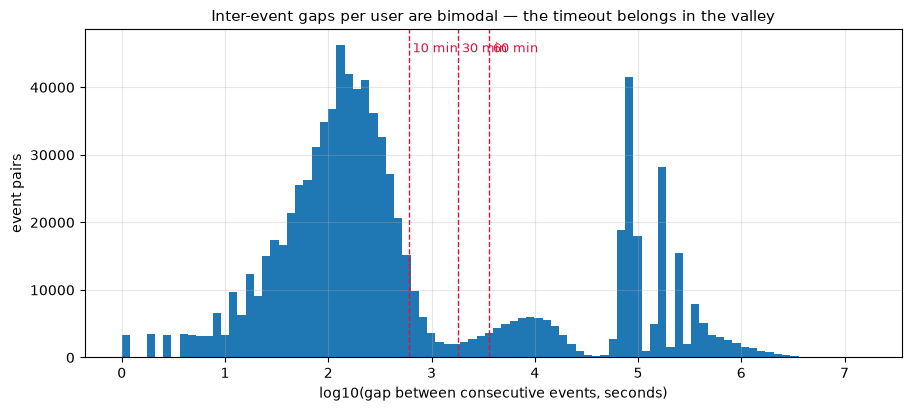

In [15]:
gaps_df = q("""
SELECT datediff('second', LAG(ts) OVER (PARTITION BY user_id ORDER BY ts), ts) AS gap_s
FROM events
QUALIFY gap_s IS NOT NULL AND gap_s > 0
""")

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(np.log10(gaps_df["gap_s"]), bins=90, color="tab:blue")
for sec, lab in [(600, "10 min"), (1800, "30 min"), (3600, "60 min")]:
    ax.axvline(np.log10(sec), color="crimson", ls="--", lw=1)
    ax.text(np.log10(sec), ax.get_ylim()[1] * 0.93, f" {lab}", color="crimson", fontsize=9)
ax.set(title="Inter-event gaps per user are bimodal — the timeout belongs in the valley",
       xlabel="log10(gap between consecutive events, seconds)", ylabel="event pairs")
plt.show()

In [16]:
con.execute("""
CREATE OR REPLACE TEMP TABLE sessions AS
WITH ordered AS (
    SELECT user_id, ts,
           datediff('second', LAG(ts) OVER (PARTITION BY user_id ORDER BY ts), ts) AS gap_s
    FROM events
),
flagged AS (
    SELECT user_id, ts,
           CASE WHEN gap_s IS NULL OR gap_s > 1800 THEN 1 ELSE 0 END AS new_session
    FROM ordered
),
numbered AS (
    SELECT user_id, ts,
           SUM(new_session) OVER (PARTITION BY user_id ORDER BY ts) AS session_seq
    FROM flagged
)
SELECT user_id, session_seq,
       MIN(ts) AS session_start,
       MAX(ts) AS session_end,
       COUNT(*) AS depth,
       datediff('second', MIN(ts), MAX(ts)) / 60.0 AS duration_min
FROM numbered
GROUP BY 1, 2
""")

sess_stats = q("""
SELECT COUNT(*)                                        AS n_sessions,
       COUNT(DISTINCT user_id)                         AS n_users,
       ROUND(AVG(depth), 2)                            AS mean_depth,
       median(depth)                                   AS median_depth,
       ROUND(AVG(duration_min), 2)                     AS mean_dur_min,
       ROUND(median(duration_min), 2)                  AS median_dur_min,
       ROUND(100.0 * AVG(CASE WHEN depth = 1 THEN 1 ELSE 0 END), 1) AS pct_single_event
FROM sessions
""")
print(sess_stats.to_string(index=False))

n_rec = int(sess_stats["n_sessions"].iloc[0])
print(f"\nrecovered sessions: {n_rec:,} vs generated ground truth {TRUE_N_SESSIONS:,} "
      f"({100 * n_rec / TRUE_N_SESSIONS - 100:+.1f}%)")
assert abs(n_rec / TRUE_N_SESSIONS - 1) < 0.06
print("(the shortfall is real behavior: sessions that started < 30 min apart get merged)")

 n_sessions  n_users  mean_depth  median_depth  mean_dur_min  median_dur_min  pct_single_event
     234491     7174        3.66           3.0          8.42             6.1               9.1

recovered sessions: 234,491 vs generated ground truth 246,813 (-5.0%)
(the shortfall is real behavior: sessions that started < 30 min apart get merged)


Depth and duration are heavily right-skewed, and ~9% of sessions are
**single-event bounces with duration exactly 0** — a measurement artifact of
"duration = last event − first event" (there is no "session end" event). Mean
session duration is therefore pulled in two directions at once (zeros down,
whales up); report medians or the full distribution, never just the mean.
The timeout-sensitivity table is the robustness check interviewers like to
hear: relaxing the timeout from 30 to 60 minutes moves session counts only
~−5%, tightening to 10 minutes moves them ~+12% — small effects for a 6×
range in the threshold, which is what a clean valley buys you.

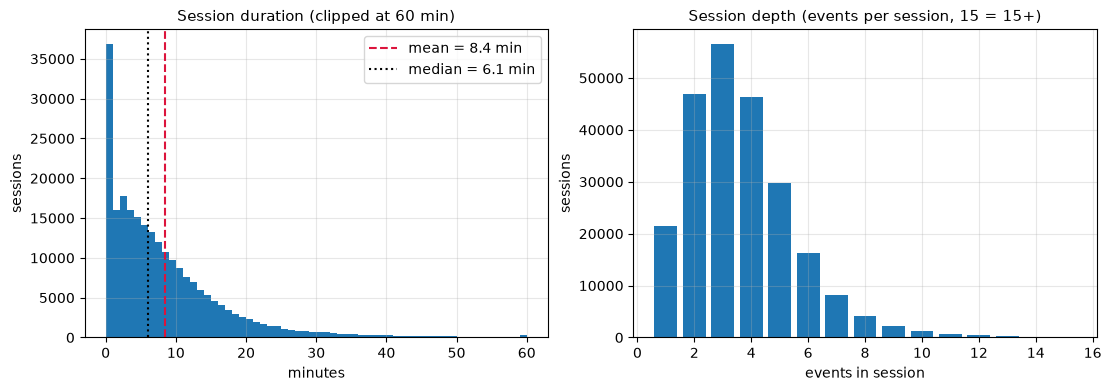

,sessions_10min,sessions_30min,sessions_60min
0,262939,234491,223938


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
dur = q("SELECT duration_min FROM sessions")["duration_min"]
axes[0].hist(dur.clip(upper=60), bins=60, color="tab:blue")
axes[0].axvline(dur.mean(), color="crimson", ls="--", label=f"mean = {dur.mean():.1f} min")
axes[0].axvline(dur.median(), color="black", ls=":", label=f"median = {dur.median():.1f} min")
axes[0].set(title="Session duration (clipped at 60 min)", xlabel="minutes", ylabel="sessions")
axes[0].legend()

depth = q("SELECT depth FROM sessions")["depth"]
depth_counts = depth.clip(upper=15).value_counts().sort_index()
axes[1].bar(depth_counts.index, depth_counts.to_numpy(), color="tab:blue")
axes[1].set(title="Session depth (events per session, 15 = 15+)",
            xlabel="events in session", ylabel="sessions")
plt.show()

q("""
WITH ordered AS (
    SELECT datediff('second', LAG(ts) OVER (PARTITION BY user_id ORDER BY ts), ts) AS gap_s
    FROM events
)
SELECT COUNT(*) FILTER (WHERE gap_s IS NULL OR gap_s > 600)  AS sessions_10min,
       COUNT(*) FILTER (WHERE gap_s IS NULL OR gap_s > 1800) AS sessions_30min,
       COUNT(*) FILTER (WHERE gap_s IS NULL OR gap_s > 3600) AS sessions_60min
FROM ordered
""")

## 6. Growth accounting: new / retained / resurrected / churned

MAU is a stock; growth accounting decomposes its flows. For each user-month:

- **new**: first month ever active;
- **retained**: active this month *and* last month;
- **resurrected**: active this month, not last month, and not new;
- **churned** (counted against month *m*): active in *m−1* but not in *m*.

These definitions make the **MAU bridge** an identity, not an approximation:
`MAU(m) = MAU(m−1) + new(m) + resurrected(m) − churned(m)` — we assert it
below. The **quick ratio** `(new + resurrected) / churned` summarizes whether
the bucket is filling faster than it leaks (consumer products typically live
around 1.0–1.5). The metric-design view of this material is in
[../08_product_analytics/01_metrics_and_growth.ipynb](../08_product_analytics/01_metrics_and_growth.ipynb);
here we care about the SQL: one `DISTINCT` collapse to user-months, then
`LAG`/`LEAD` per user.

In [18]:
ga = q("""
WITH monthly AS (
    SELECT DISTINCT user_id, date_trunc('month', ts)::DATE AS month FROM events
),
flows AS (
    SELECT user_id, month,
           LAG(month)  OVER (PARTITION BY user_id ORDER BY month) AS prev_m,
           LEAD(month) OVER (PARTITION BY user_id ORDER BY month) AS next_m,
           MIN(month)  OVER (PARTITION BY user_id)                AS first_m
    FROM monthly
),
inflow AS (
    SELECT month,
           COUNT(*)                                                    AS mau,
           COUNT(*) FILTER (WHERE month = first_m)                     AS new_users,
           COUNT(*) FILTER (WHERE datediff('month', prev_m, month) = 1) AS retained,
           COUNT(*) FILTER (WHERE month > first_m
                              AND datediff('month', prev_m, month) > 1) AS resurrected
    FROM flows GROUP BY 1
),
outflow AS (      -- churn charged to the first inactive month
    SELECT (month + INTERVAL 1 MONTH)::DATE AS month, COUNT(*) AS churned
    FROM flows
    WHERE (next_m IS NULL OR datediff('month', month, next_m) > 1)
      AND month < DATE '2024-12-01'
    GROUP BY 1
)
SELECT i.month, i.mau, i.new_users, i.retained, i.resurrected,
       COALESCE(o.churned, 0) AS churned
FROM inflow i LEFT JOIN outflow o USING (month)
ORDER BY 1
""")

# the MAU bridge must hold exactly
lhs = ga["mau"].iloc[1:].to_numpy()
rhs = (ga["mau"].shift(1) + ga["new_users"] + ga["resurrected"] - ga["churned"]).iloc[1:].to_numpy()
assert np.array_equal(lhs, rhs.astype(int)), "MAU bridge identity violated"
print("MAU bridge holds exactly for all months: MAU(m) = MAU(m-1) + new + resurrected - churned")

ga["quick_ratio"] = ((ga["new_users"] + ga["resurrected"]) / ga["churned"]).where(ga["churned"] > 0)
ga_show = ga.assign(month=ga["month"].dt.strftime("%Y-%m")).round({"quick_ratio": 2})
print(ga_show.to_string(index=False))

MAU bridge holds exactly for all months: MAU(m) = MAU(m-1) + new + resurrected - churned
  month  mau  new_users  retained  resurrected  churned  quick_ratio
2024-01  276        276         0            0        0          NaN
2024-02  492        284       208            0       68         4.18
2024-03  705        321       379            5      113         2.88
2024-04  929        339       571           19      134         2.67
2024-05 1162        390       749           23      180         2.29
2024-06 1402        411       972           19      190         2.26
2024-07 1652        465      1163           24      239         2.05
2024-08 1908        499      1366           43      286         1.90
2024-09 2192        534      1616           42      292         1.97
2024-10 3006       1080      1874           52      318         3.56
2024-11 3620       1258      2316           46      690         1.89
2024-12 4130       1317      2705          108      915         1.56


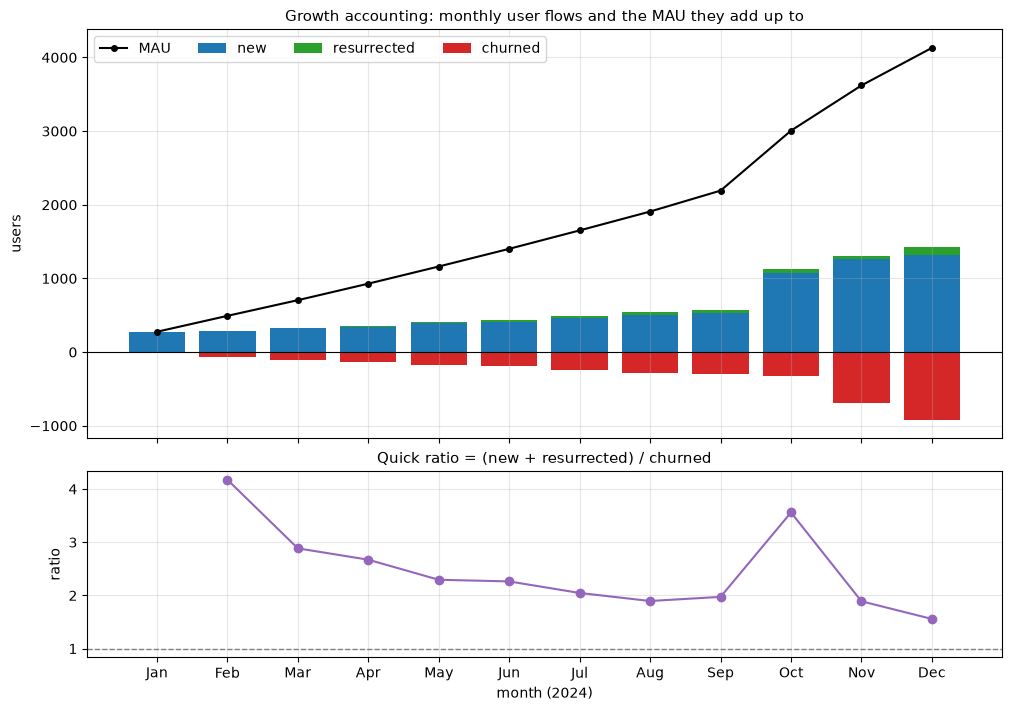

In [19]:
m_lab = ga["month"].dt.strftime("%b")
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True,
                         gridspec_kw={"height_ratios": [2.2, 1]})
ax = axes[0]
ax.bar(m_lab, ga["new_users"], color="tab:blue", label="new")
ax.bar(m_lab, ga["resurrected"], bottom=ga["new_users"], color="tab:green", label="resurrected")
ax.bar(m_lab, -ga["churned"], color="tab:red", label="churned")
ax.plot(m_lab, ga["mau"], color="black", marker="o", ms=4, label="MAU")
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Growth accounting: monthly user flows and the MAU they add up to",
       ylabel="users")
ax.legend(ncols=4, loc="upper left")

axq = axes[1]
axq.plot(m_lab, ga["quick_ratio"], marker="o", color="tab:purple")
axq.axhline(1.0, color="gray", ls="--", lw=1)
axq.set(title="Quick ratio = (new + resurrected) / churned", ylabel="ratio", xlabel="month (2024)")
plt.show()

Reading it like an operator: through September the bucket fills — churn is
modest and the quick ratio sits comfortably above 1. The campaign then
produces a huge `new` bar in Oct–Nov **and** a matching `churned` explosion
one month later, crushing the quick ratio — MAU keeps rising while its
*composition* rots. This is why growth accounting belongs next to MAU on any
exec dashboard: the headline stock can grow while every flow underneath
deteriorates. (For modeling *who* churns rather than counting churn, see
[../08_product_analytics/02_churn_survival.ipynb](../08_product_analytics/02_churn_survival.ipynb).)

## 7. The L28 engagement distribution — why averages hide bimodality

"Days active in the last 28" (L28, a.k.a. the engagement or power-user curve)
is the single most informative engagement summary: for every user active in
the trailing 28 days, count *how many* of those days they showed up. Its
shape, not its mean, is the product diagnosis:

- a **left spike** (1–4 days) = shallow majority, monetize with reach;
- a **right mode** (mid-teens here; 20+ for daily-habit products) = habitual
  core, monetize with subscription;
- both at once = a **bimodal** base that no single "average user" describes.

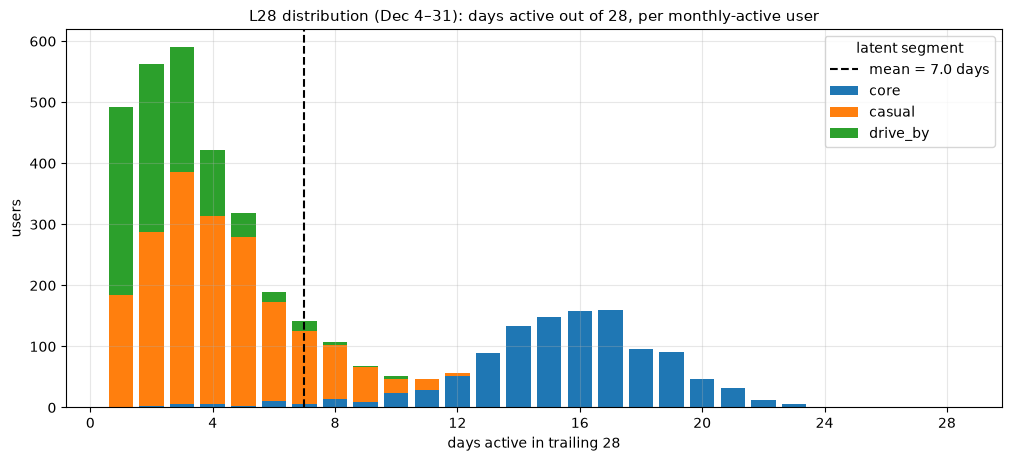

mean = 7.0 days, median = 4 days, share <= 4 days: 51%, share >= 12 days: 26%
users within +/-2 days of the mean: 19% — the 'average user' barely exists


In [20]:
l28 = q("""
SELECT e.user_id, u.segment, COUNT(DISTINCT e.ts::DATE) AS days_active
FROM events e JOIN users u USING (user_id)
WHERE e.ts::DATE BETWEEN DATE '2024-12-04' AND DATE '2024-12-31'
GROUP BY 1, 2
""")

counts = (l28.groupby(["days_active", "segment"]).size().unstack(fill_value=0)
          .reindex(range(1, 29), fill_value=0)[["core", "casual", "drive_by"]])
fig, ax = plt.subplots(figsize=(10, 4.5))
bottom = np.zeros(28)
for seg_name in counts.columns:
    ax.bar(counts.index, counts[seg_name], bottom=bottom,
           color=SEG_COLORS[seg_name], label=seg_name)
    bottom += counts[seg_name].to_numpy()
mean_da = l28["days_active"].mean()
ax.axvline(mean_da, color="black", ls="--", label=f"mean = {mean_da:.1f} days")
ax.set(title="L28 distribution (Dec 4–31): days active out of 28, per monthly-active user",
       xlabel="days active in trailing 28", ylabel="users", xticks=range(0, 29, 4))
ax.legend(title="latent segment")
plt.show()

share_low = (l28["days_active"] <= 4).mean()
share_high = (l28["days_active"] >= 12).mean()
print(f"mean = {mean_da:.1f} days, median = {l28['days_active'].median():.0f} days, "
      f"share <= 4 days: {100 * share_low:.0f}%, share >= 12 days: {100 * share_high:.0f}%")
print(f"users within +/-2 days of the mean: "
      f"{100 * ((l28['days_active'] - mean_da).abs() <= 2).mean():.0f}% — the 'average user' barely exists")

The latent segments (which real analysts don't observe!) confirm what the
shape alone suggests: the left spike is casual/campaign users, the right mode
is the core. Any metric of the form "average days active" or "average
sessions per user" collapses this mixture into a number that describes almost
nobody — the same lesson as mean-vs-distribution for session duration, and
the reason the L28 histogram (not its mean) belongs on the dashboard.
Segmenting this distribution properly is the subject of
[../08_product_analytics/04_segmentation_clustering.ipynb](../08_product_analytics/04_segmentation_clustering.ipynb).

## 8. Pitfalls

Each of these is a mistake that ships to real dashboards weekly. All three are
demonstrated on our data, where we know the truth being distorted.

**Pitfall 1 — pooling retention across cohorts (immature cohorts and mix
shifts).** A "blended retention curve" pools cohorts of different ages and
quality. Two distinct failure modes: (a) *wrong denominator* — including
users who haven't been observed long enough to possibly retain at horizon N
crushes the tail of the curve; (b) *composition* — even with correct
denominators, the pooled curve mixes cohort quality into the tenure shape
(here: campaign cohorts drag down early weeks, and only old — better —
cohorts survive into late weeks, flattering the tail). Slice by cohort;
pool only deliberately.

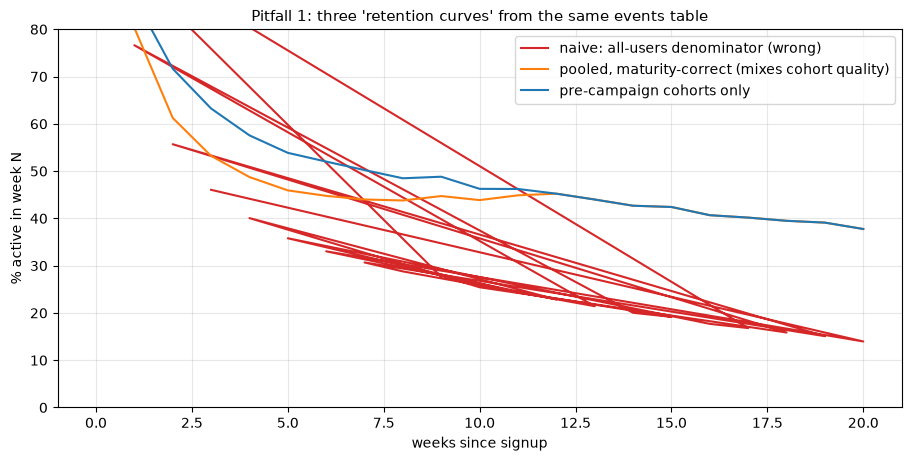

        naive_pct  pooled_correct_pct  pre_campaign_pct
week_n                                                 
1            76.6                80.3              86.7
4            40.1                48.7              57.6
8            28.8                43.8              48.5
12           22.8                45.2              45.2


In [21]:
# correct-maturity pooled curve vs naive-denominator curve vs pre-campaign-only
naive_long = q("""
WITH su AS (
    SELECT user_id, date_trunc('week', MIN(ts))::DATE AS cohort_week
    FROM events WHERE event_name = 'signup' GROUP BY 1
),
act AS (
    SELECT DISTINCT user_id, date_trunc('week', ts)::DATE AS act_week
    FROM events WHERE ts < TIMESTAMP '2024-12-30 00:00:00'
)
SELECT (a.act_week - su.cohort_week) // 7 AS week_n, COUNT(DISTINCT a.user_id) AS actives
FROM su JOIN act a USING (user_id)
WHERE a.act_week >= su.cohort_week
GROUP BY 1
""")
total_users = int(q("SELECT COUNT(DISTINCT user_id) FROM events").iloc[0, 0])
naive = naive_long.assign(retention_pct=lambda d: 100 * d["actives"] / total_users)

pooled = (wk_long.groupby("week_n")[["actives", "cohort_size"]].sum()
          .assign(retention_pct=lambda d: 100 * d["actives"] / d["cohort_size"]))
pre_camp = (wk_long[wk_long["cohort_week"] < pd.Timestamp("2024-10-07")]
            .groupby("week_n")[["actives", "cohort_size"]].sum()
            .assign(retention_pct=lambda d: 100 * d["actives"] / d["cohort_size"]))

fig, ax = plt.subplots(figsize=(9, 4.5))
W = 20
ax.plot(naive["week_n"][naive["week_n"] <= W], naive["retention_pct"][naive["week_n"] <= W],
        color="tab:red", label="naive: all-users denominator (wrong)")
ax.plot(pooled.index[pooled.index <= W], pooled["retention_pct"][pooled.index <= W],
        color="tab:orange", label="pooled, maturity-correct (mixes cohort quality)")
ax.plot(pre_camp.index[pre_camp.index <= W], pre_camp["retention_pct"][pre_camp.index <= W],
        color="tab:blue", label="pre-campaign cohorts only")
ax.set(title="Pitfall 1: three 'retention curves' from the same events table",
       xlabel="weeks since signup", ylabel="% active in week N", ylim=(0, 80))
ax.legend()
plt.show()

cmp = pd.DataFrame({
    "naive_pct": naive.set_index("week_n")["retention_pct"],
    "pooled_correct_pct": pooled["retention_pct"],
    "pre_campaign_pct": pre_camp["retention_pct"],
}).loc[[1, 4, 8, 12]].round(1)
print(cmp)

**Pitfall 2 — "active user" is a definition, not a fact.** Counting *any*
event (including `app_open` pings) vs counting *engagement* events (`play`,
`complete`) cuts December DAU by ~25% but MAU by only ~8% — the strict
definition bites hardest on low-intensity user-days, so it changes the
frequency story more than the reach story. And the engaged/any ratio drifts
over time (dipping as campaign users flood in), so one definition is not a
fixed rescaling of the other. Fix the definition in a shared metrics layer,
version it, and re-state history when it changes.

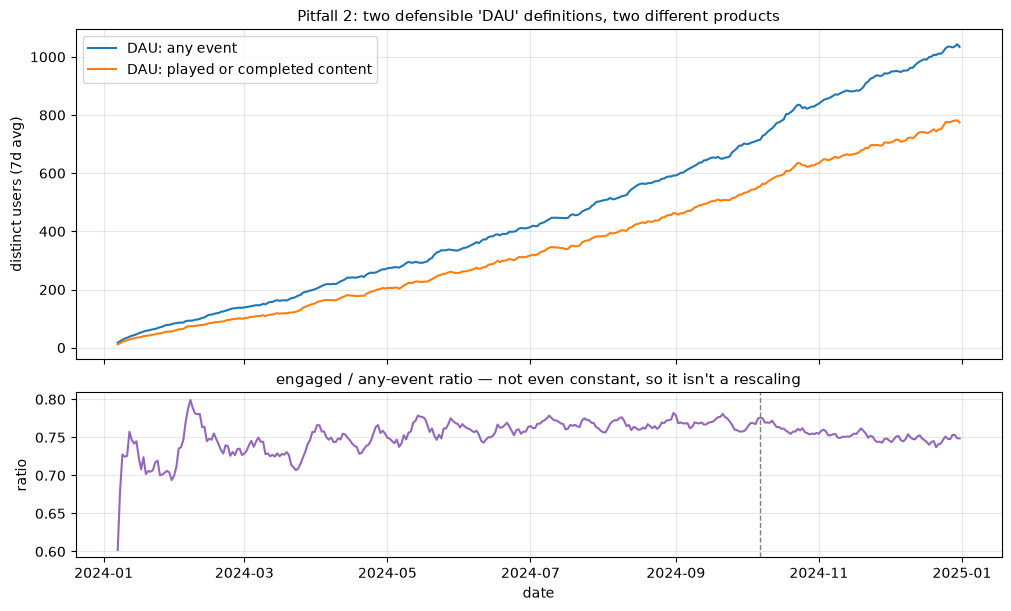

December: MAU(any) = 4,130, MAU(engaged) = 3,815  (-8%)
December avg DAU gap: -25% — DAU moves more than MAU because the definition bites hardest on low-intensity days


In [22]:
dau_defs = q("""
SELECT ts::DATE AS day,
       COUNT(DISTINCT user_id) AS dau_any_event,
       COUNT(DISTINCT user_id) FILTER (WHERE event_name IN ('play', 'complete')) AS dau_engaged
FROM events
GROUP BY 1 ORDER BY 1
""")
dau_defs["ratio"] = dau_defs["dau_engaged"] / dau_defs["dau_any_event"]

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True,
                         gridspec_kw={"height_ratios": [2, 1]})
axes[0].plot(dau_defs["day"], dau_defs["dau_any_event"].rolling(7).mean(),
             color="tab:blue", label="DAU: any event")
axes[0].plot(dau_defs["day"], dau_defs["dau_engaged"].rolling(7).mean(),
             color="tab:orange", label="DAU: played or completed content")
axes[0].set(title="Pitfall 2: two defensible 'DAU' definitions, two different products",
            ylabel="distinct users (7d avg)")
axes[0].legend()
axes[1].plot(dau_defs["day"], dau_defs["ratio"].rolling(7).mean(), color="tab:purple")
axes[1].axvline(pd.Timestamp("2024-10-07"), color="gray", ls="--", lw=1)
axes[1].set(title="engaged / any-event ratio — not even constant, so it isn't a rescaling",
            ylabel="ratio", xlabel="date")
plt.show()

mau_defs = q("""
SELECT COUNT(DISTINCT user_id) AS mau_any,
       COUNT(DISTINCT user_id) FILTER (WHERE event_name IN ('play', 'complete')) AS mau_engaged
FROM events WHERE ts::DATE BETWEEN DATE '2024-12-01' AND DATE '2024-12-31'
""")
ma, me = mau_defs.iloc[0]
print(f"December: MAU(any) = {ma:,}, MAU(engaged) = {me:,}  ({100 * me / ma - 100:+.0f}%)")
print(f"December avg DAU gap: {100 * dau_defs.set_index('day').loc['2024-12', 'ratio'].mean() - 100:+.0f}% "
      "— DAU moves more than MAU because the definition bites hardest on low-intensity days")

**Pitfall 3 — calendar artifacts in DAU comparisons.** Day-of-week seasonality
means naive day-over-day or misaligned week-over-week deltas are dominated by
the calendar, not the product. The cure: compare same-weekday (or 7-day
aggregates), and never quote "DAU changed X%" across an unequal weekday mix.
Calendar months have the same problem in miniature (28–31-day lengths, which
is why rolling-28 beats calendar MAU for trend reading).

In [23]:
d = activity.set_index("day")["dau"]
mon, sat = pd.Timestamp("2024-11-25"), pd.Timestamp("2024-11-30")
print(f"'DAU dropped {100 * d[sat] / d[mon] - 100:.0f}%!!' — Mon {mon.date()} = {d[mon]:,} "
      f"vs Sat {sat.date()} = {d[sat]:,}  (it's just Saturday)")
prev_sat = sat - pd.Timedelta(days=7)
print(f"same-weekday comparison: Sat {prev_sat.date()} = {d[prev_sat]:,} -> Sat {sat.date()} = {d[sat]:,} "
      f"({100 * d[sat] / d[prev_sat] - 100:+.1f}%) — the honest number")
week_a = d.loc["2024-11-18":"2024-11-24"].mean()
week_b = d.loc["2024-11-25":"2024-12-01"].mean()
print(f"aligned full weeks: {week_a:.0f} -> {week_b:.0f} ({100 * week_b / week_a - 100:+.1f}%)")

'DAU dropped -26%!!' — Mon 2024-11-25 = 1,058 vs Sat 2024-11-30 = 787  (it's just Saturday)
same-weekday comparison: Sat 2024-11-23 = 793 -> Sat 2024-11-30 = 787 (-0.8%) — the honest number
aligned full weeks: 928 -> 944 (+1.8%)


## Interview corner

**1. "Define retention. Now compute it."**
Start by pinning four choices: (a) grain — day/week/month brackets matched to
the product's natural frequency; (b) bounded ("active on exactly day N") vs
unbounded ("day N or later" — right-censored, keeps drifting up for recent
cohorts); (c) the activity definition (which events qualify); (d) the
denominator — full cohort, only cohorts observed ≥ N periods. Then the SQL:
first-seen per user (`MIN(ts)`), distinct user-periods, join, bucket by
`datediff`, divide by cohort size. Bonus: say when you'd reach for survival
methods instead (censoring, covariates).

**2. "DAU is flat but MAU is growing. What story fits?"**
Stickiness (DAU/MAU) is falling — the user base is growing while per-user
frequency shrinks. Consistent stories: acquisition of low-frequency users
(our campaign: reach up, frequency down), engagement decay in existing users
offset by new-user inflow, or a product shift from daily to episodic use.
Diagnose with: the L28 distribution over time (left spike growing?), growth
accounting (is `new` masking `churned`?), and DAU decomposed into
new-vs-existing users. The one story that *doesn't* fit: "everything is fine."

**3. "Write a funnel query."**
Narrate the semantics before the SQL: entry anchor and conversion window,
strict ordering (each step after the previous step's first qualifying event),
per-user dedup (count users, not events), exclusion of entrants without a full
window. Then either chained CTEs with constrained `MIN(ts)` per step, or
stacked window layers (`MIN(CASE ...) OVER (PARTITION BY user_id)`) whose
`NULL`s cascade. Mention the reconciliation check: strict-funnel completions
vs total goal events (alternate paths, out-of-window conversions).

**4. "How would you define an active user?"**
"Depends what action delivers the product's value — I'd exclude passive
opens/notifications and count value events (here: played content)." Then the
senior add-ons: definition sensitivity analysis (Pitfall 2 — the two
definitions diverge *differentially* over time), robustness to instrumentation
changes, one definition in a shared metrics layer rather than per-dashboard
ad-hockery, and the reporting window (DAU vs WAU vs MAU28) matched to natural
frequency.

**5. "Sessionize this event log. What are the edge cases?"**
`LAG` per user ordered by ts → gap; gap > timeout starts a session; running
`SUM` of start-flags = session ID; aggregate for depth/duration. Edge cases:
timeout choice (justify from the bimodal gap distribution, show 10/30/60-min
sensitivity), midnight-crossing sessions (sessionize on timestamps, then
assign to a day — commonly the session-start day), multi-device users
(dedupe or partition by device), clock skew and late-arriving events,
single-event sessions making duration = 0, and server events (webhooks)
polluting client sessions.

**6. "MAU grew 10% last month. Good news?"**
Unclear until decomposed: `ΔMAU = new + resurrected − churned`. If growth came
from a `new` spike while `churned` also spiked (our Q4), you bought a leaky
cohort — check the quick ratio and the next month's churn. Also check the
calendar (31-day vs 30-day month, campaign timing) and whether *engaged* MAU
(stricter definition) grew too.

**7. "Why isn't WAU equal to average DAU × 7? What does DAU/WAU tell you?"**
Distinct counts don't add: the same user on 5 days is 5 DAU-contributions but
1 WAU-contribution. DAU/WAU = average fraction of weekly actives who show up
per day = a frequency measure (bounded by 1/7 from below when everyone comes
once). The whole DAU→WAU→MAU ladder is one distribution — days-active — read
at different windows; the L28 histogram is that distribution made visible.

**8. "Our retention curve flattens at 35% after week 8. Is that good?"**
Flattening itself is the good news — a habitual segment exists (retention
curves that never flatten mean permanent leakage). Whether 35% is *good*
depends on category benchmarks and on what the plateau is made of (which
users, at what frequency, monetizing how). Watch whether newer cohorts
flatten higher (improving product/mix) — and whether the plateau survives a
change in acquisition mix, which is what LTV models consume
(../08_product_analytics/03_ltv_modeling.ipynb).

## Key takeaways

- Product analytics SQL is three moves composed: **distinct-collapse** to
  user-periods, **first-seen anchoring** (`MIN(ts)` per user), and **window
  functions over user timelines** (`LAG`, running `SUM`). Every metric here is
  built from them.
- Distinct counts are not additive: WAU ≠ 7×DAU, rolling distinct counts need
  a range join or the interval sweep-line — never a windowed `SUM` of DAU.
- Say *which* retention: bounded vs unbounded vs bracketed; full-cohort
  denominators; only cohorts mature enough for the horizon. Unbounded numbers
  are right-censored and 2–3× the bounded ones.
- The cohort triangle separates tenure (rows) from cohort quality (columns);
  a flattening curve is the PMF signal, and the flattening *level* is a
  composition statement.
- Strict funnels measure the intended path, not goal attainment — reconcile
  the last step against raw goal events, exclude entrants without a full
  conversion window, and state the ordering/matching semantics explicitly.
- Sessions are a definition, not a fact: justify the timeout from the bimodal
  gap distribution, show threshold sensitivity, and report median (not mean)
  duration.
- Growth accounting turns MAU into an exact bridge: new + resurrected −
  churned. A growing MAU with a collapsing quick ratio is bought, not earned.
- Averages hide the two distributions that matter: days-active (bimodal L28)
  and session duration (zero-inflated, right-skewed). Ship the histogram.
- The same campaign left fingerprints in every section — stickiness,
  triangle, growth accounting, L28. Real metric work is cross-checking these
  views against each other, not computing any one of them.

## Exercises

**Exercise 1.** Compute D7 retention by *monthly* signup cohort, both bounded
and unbounded, in one query (exclude the December cohort — it lacks a full 7
days of observation for late signups). Which definition makes newer cohorts
look better, and why is the unbounded number for recent cohorts not final?

**Exercise 2.** Using the `sessions` table, compute per-segment session
metrics: bounce rate (share of single-event sessions), median depth, and
median duration. (Join the ground-truth `users` table.) Do the segments
differ more in *how often* they show up or in *what a session looks like*?

**Exercise 3.** Re-run the strict funnel with 7-, 14-, 30- and 60-day
conversion windows. Which step's conversion is most window-sensitive, and
what product mechanic explains it?

In [24]:
# --- Solution 1 -------------------------------------------------------------
sol1 = q("""
WITH su AS (
    SELECT user_id, MIN(ts)::DATE AS d0,
           date_trunc('month', MIN(ts))::DATE AS cohort_month
    FROM events WHERE event_name = 'signup' GROUP BY 1
),
act AS (SELECT DISTINCT user_id, ts::DATE AS day FROM events),
tenure AS (
    SELECT su.user_id, su.cohort_month, (a.day - su.d0)::INT AS n
    FROM su JOIN act a USING (user_id)
    WHERE a.day >= su.d0
)
SELECT cohort_month,
       COUNT(DISTINCT user_id)                                    AS cohort_size,
       ROUND(100.0 * COUNT(DISTINCT user_id) FILTER (WHERE n = 7)
             / COUNT(DISTINCT user_id), 1)                        AS d7_bounded_pct,
       ROUND(100.0 * COUNT(DISTINCT user_id) FILTER (WHERE n >= 7)
             / COUNT(DISTINCT user_id), 1)                        AS d7_unbounded_pct
FROM tenure
WHERE cohort_month < DATE '2024-12-01'
GROUP BY 1 ORDER BY 1
""")
print(sol1.assign(cohort_month=sol1["cohort_month"].astype(str)).to_string(index=False))
print("\nUnbounded flatters recent cohorts less than you'd think *today* but its numbers")
print("are right-censored: November signups still have most of their 'day 7 or later'")
print("observation window ahead of them, so d7_unbounded for recent cohorts will keep")
print("rising after more data arrives. Bounded D7 is final 8 days after the cohort closes.")

cohort_month  cohort_size  d7_bounded_pct  d7_unbounded_pct
  2024-01-01          276            34.1              85.1
  2024-02-01          284            34.9              85.6
  2024-03-01          321            34.9              86.9
  2024-04-01          339            36.0              84.1
  2024-05-01          390            35.4              85.1
  2024-06-01          411            38.9              86.4
  2024-07-01          465            40.2              88.8
  2024-08-01          499            37.7              89.2
  2024-09-01          534            39.5              88.2
  2024-10-01         1080            23.9              73.3
  2024-11-01         1258            23.3              68.0

Unbounded flatters recent cohorts less than you'd think *today* but its numbers
are right-censored: November signups still have most of their 'day 7 or later'
observation window ahead of them, so d7_unbounded for recent cohorts will keep
rising after more data arrives. Bounded D

In [25]:
# --- Solution 2 -------------------------------------------------------------
sol2 = q("""
SELECT u.segment,
       COUNT(*)                                                     AS sessions,
       ROUND(COUNT(*) * 1.0 / COUNT(DISTINCT s.user_id), 1)         AS sessions_per_user,
       ROUND(100.0 * AVG(CASE WHEN s.depth = 1 THEN 1 ELSE 0 END), 1) AS bounce_pct,
       median(s.depth)                                              AS median_depth,
       ROUND(median(s.duration_min), 1)                             AS median_dur_min
FROM sessions s JOIN users u USING (user_id)
GROUP BY 1 ORDER BY sessions DESC
""")
print(sol2.to_string(index=False))
print("\nWithin-session behavior (depth, duration, bounce) differs only modestly across")
print("segments — the big differences are in frequency and lifetime (sessions_per_user).")
print("That is typical: engagement tiers usually diverge in *how often*, not *how deep*.")

 segment  sessions  sessions_per_user  bounce_pct  median_depth  median_dur_min
    core    160484              129.4         7.6           4.0             6.7
  casual     62814               19.6        11.4           3.0             5.3
drive_by     11193                4.1        18.9           2.0             3.2

Within-session behavior (depth, duration, bounce) differs only modestly across
segments — the big differences are in frequency and lifetime (sessions_per_user).
That is typical: engagement tiers usually diverge in *how often*, not *how deep*.


In [26]:
# --- Solution 3 -------------------------------------------------------------
rows = []
for window in (7, 14, 30, 60):
    row = q(f"""
    WITH p0 AS (SELECT user_id, MIN(ts) AS t0 FROM events
                WHERE event_name = 'signup'
                  AND ts <= TIMESTAMP '2024-12-31 23:59:59' - INTERVAL {window} DAY
                GROUP BY 1),
    p1 AS (SELECT p0.user_id, t0, MIN(e.ts) AS t1 FROM p0 JOIN events e
           ON e.user_id = p0.user_id AND e.event_name = 'play'
           AND e.ts > t0 AND e.ts <= t0 + INTERVAL {window} DAY GROUP BY 1, 2),
    p2 AS (SELECT p1.user_id, t0, MIN(e.ts) AS t2 FROM p1 JOIN events e
           ON e.user_id = p1.user_id AND e.event_name = 'view_paywall'
           AND e.ts > t1 AND e.ts <= t0 + INTERVAL {window} DAY GROUP BY 1, 2),
    p3 AS (SELECT p2.user_id, t0, MIN(e.ts) AS t3 FROM p2 JOIN events e
           ON e.user_id = p2.user_id AND e.event_name = 'trial_start'
           AND e.ts > t2 AND e.ts <= t0 + INTERVAL {window} DAY GROUP BY 1, 2),
    p4 AS (SELECT p3.user_id, t0, MIN(e.ts) AS t4 FROM p3 JOIN events e
           ON e.user_id = p3.user_id AND e.event_name = 'subscribe'
           AND e.ts > t3 AND e.ts <= t0 + INTERVAL {window} DAY GROUP BY 1, 2)
    SELECT (SELECT COUNT(*) FROM p0) AS signup, (SELECT COUNT(*) FROM p1) AS play,
           (SELECT COUNT(*) FROM p2) AS paywall, (SELECT COUNT(*) FROM p3) AS trial,
           (SELECT COUNT(*) FROM p4) AS subscribe
    """).iloc[0]
    rows.append({"window_days": window,
                 **{f"pct_{k}": round(100 * row[k] / row["signup"], 1)
                    for k in ("play", "paywall", "trial", "subscribe")}})
sol3 = pd.DataFrame(rows)
print(sol3.to_string(index=False))
print("\nThe subscribe step is by far the most window-sensitive: the product has a 7-day")
print("trial, so subscriptions mechanically occur >= ~7 days after trial start — a 7-day")
print("window cannot contain trial + conversion and reports ~0%. Conversion windows must")
print("respect product mechanics, or the funnel measures the window, not the product.")

 window_days  pct_play  pct_paywall  pct_trial  pct_subscribe
           7      86.6         32.8        7.3            0.0
          14      89.9         45.2       11.5            3.5
          30      91.6         56.5       14.9            7.1
          60      93.7         65.8       17.3            8.5

The subscribe step is by far the most window-sensitive: the product has a 7-day
trial, so subscriptions mechanically occur >= ~7 days after trial start — a 7-day
window cannot contain trial + conversion and reports ~0%. Conversion windows must
respect product mechanics, or the funnel measures the window, not the product.
